# IS 507 · Medicaid Enrollment Data Preparation

**Project:** GLP-1 Utilization & Health Needs Across U.S. States  
**Dataset:** CMS *State Medicaid and CHIP Applications, Eligibility Determinations, and Enrollment Data*, October 2026 release  
**Goal:** Produce **2025 average Medicaid enrollment per state and quarter**, for the denominator of the team's GLP-1 prescription rate.

> Jupyter Notebook files (`.ipynb`) run **Python in separate cells**. Work through the cells from top to bottom using **Shift + Enter** or **Run All**.

**Setup:** Place this notebook and `pi-dataset-october-2026-release.csv` in the **same folder**. Uses `pandas` and `matplotlib` (install them in your notebook environment if needed).

## 1 · Import libraries and locate the original CSV

We use `pandas` to inspect, filter, and summarize the data. `Path.cwd()` refers to the folder where your Jupyter Notebook is running.

In [28]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

folder = Path.cwd()
source_file = folder / "pi-dataset-october-2026-release.csv"
assert source_file.exists(), (
    f"Missing file: {source_file}. Place the original CMS CSV next to this notebook."
)
print("Source:", source_file.name)

Source: pi-dataset-october-2026-release.csv


## 2 · Load the file and inspect its structure

The source includes both Medicaid and CHIP indicators and several years of monthly records. We only need **Medicaid enrollment for 2025**.

In [29]:
df = pd.read_csv(
    source_file,
    dtype={"Reporting Period": "string"},
    low_memory=False
)
print(f"Original dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df[[
    "State Abbreviation", "State Name", "Reporting Period",
    "Preliminary or Updated", "Final Report", "Total Medicaid Enrollment"
]].head())

Original dataset: 11,220 rows × 44 columns


,State Abbreviation,State Name,Reporting Period,Preliminary or Updated,Final Report,Total Medicaid Enrollment
0,AK,Alaska,201309,U,Y,NaN
1,AK,Alaska,201706,P,N,179001.0
2,AK,Alaska,201706,U,Y,182080.0
3,AK,Alaska,201707,P,N,180641.0
4,AK,Alaska,201707,U,Y,183516.0


## 3 · Filter to 2025 updated/final records

The CMS dataset includes **preliminary (`P`)** and **updated (`U`)** observations. For this release, the updated records are also marked `Final Report = Y`. We keep only those to avoid double-counting a month.

In [30]:
is_2025 = df["Reporting Period"].str.startswith("2025", na=False)
is_updated = df["Preliminary or Updated"].eq("U")
is_final = df["Final Report"].eq("Y")

selected = df.loc[is_2025 & is_updated & is_final].copy()
print("Updated/final monthly rows:", len(selected))
print("States / D.C.:", selected["State Abbreviation"].nunique())
print("Distinct months:", selected["Reporting Period"].nunique())

# Each state should have only one selected record per month.
assert not selected.duplicated(["State Abbreviation", "Reporting Period"]).any(), (
    "Duplicate state-month records found; review source before continuing."
)

Updated/final monthly rows: 612
States / D.C.: 51
Distinct months: 12


## 4 · Keep the right variables and build state/quarter fields

**Important:** Select `Total Medicaid Enrollment`, **not** `Total Medicaid and CHIP Enrollment` or `Total Adult Medicaid Enrollment`. The project denominator is total Medicaid enrollment, matching the team's midterm definition.

`Reporting Period` is formatted as `YYYYMM`. We extract the month and assign Q1–Q4.

In [31]:
monthly = selected[[
    "State Abbreviation", "State Name", "Reporting Period",
    "Total Medicaid Enrollment", "Total Medicaid Enrollment - footnotes"
]].rename(columns={
    "State Abbreviation": "state",
    "State Name": "state_name",
    "Reporting Period": "reporting_period",
    "Total Medicaid Enrollment": "medicaid_enrollment",
    "Total Medicaid Enrollment - footnotes": "enrollment_footnote"
}).copy()

monthly["date"] = pd.to_datetime(monthly["reporting_period"], format="%Y%m")
monthly["year"] = monthly["date"].dt.year
monthly["month"] = monthly["date"].dt.month
monthly["quarter"] = "Q" + monthly["date"].dt.quarter.astype(str)
monthly["medicaid_enrollment"] = pd.to_numeric(monthly["medicaid_enrollment"], errors="coerce")
monthly["enrollment_footnote"] = monthly["enrollment_footnote"].fillna("").astype(str).str.strip()
monthly["source_report_type"] = "Updated"
monthly["final_report"] = "Y"

monthly = monthly[[
    "state", "state_name", "year", "month", "quarter",
    "medicaid_enrollment", "source_report_type", "final_report",
    "enrollment_footnote"
]].sort_values(["state", "month"]).reset_index(drop=True)

display(monthly.head(6))

,state,state_name,year,month,quarter,medicaid_enrollment,source_report_type,final_report,enrollment_footnote
0,AK,Alaska,2025,1,Q1,231448.0,Updated,Y,
1,AK,Alaska,2025,2,Q1,229186.0,Updated,Y,
2,AK,Alaska,2025,3,Q1,228508.0,Updated,Y,
3,AK,Alaska,2025,4,Q2,224131.0,Updated,Y,
4,AK,Alaska,2025,5,Q2,211333.0,Updated,Y,
5,AK,Alaska,2025,6,Q2,211659.0,Updated,Y,


## 5 · Validate monthly observations and preserve footnotes

We should not silently replace missing enrollment with zero. We also preserve CMS footnotes because states may use different reporting conventions.

In [32]:
print("Missing Medicaid enrollment:", monthly["medicaid_enrollment"].isna().sum())
print("Nonpositive Medicaid enrollment:", (monthly["medicaid_enrollment"] <= 0).sum())
print("Monthly rows containing enrollment footnotes:", monthly["enrollment_footnote"].ne("").sum())

assert monthly["medicaid_enrollment"].notna().all(), "Missing enrollment value(s)."
assert monthly["medicaid_enrollment"].gt(0).all(), "Nonpositive enrollment value(s)."

quality_notes = monthly.loc[monthly["enrollment_footnote"].ne(""), [
    "state", "state_name", "year", "month", "enrollment_footnote"
]].copy()
quality_notes["reporting_period"] = (
    quality_notes["year"].astype(str) + quality_notes["month"].astype(str).str.zfill(2)
)
quality_notes = quality_notes[[
    "state", "state_name", "reporting_period", "enrollment_footnote"
]].rename(columns={"enrollment_footnote": "footnote"})

display(quality_notes.head())

Missing Medicaid enrollment: 0
Nonpositive Medicaid enrollment: 0
Monthly rows containing enrollment footnotes: 81


,state,state_name,reporting_period,footnote
48,CA,California,202501,Includes Limited-Benefit Enrollees
49,CA,California,202502,Includes Limited-Benefit Enrollees
50,CA,California,202503,Includes Limited-Benefit Enrollees
51,CA,California,202504,Includes Limited-Benefit Enrollees
52,CA,California,202505,Includes Limited-Benefit Enrollees


## 6 · Calculate quarterly average Medicaid enrollment

The project uses the **average of the three monthly enrollment counts within a quarter**, not their sum.

\[
\text{Average enrollment}_{s,q} =
\frac{\text{Enrollment}_{s,m_1}+\text{Enrollment}_{s,m_2}+\text{Enrollment}_{s,m_3}}{3}
\]

`has_enrollment_footnote` indicates whether at least one source month in that quarter had a CMS enrollment footnote.

In [33]:
quarterly = (
    monthly.groupby(["state", "state_name", "year", "quarter"], as_index=False)
    .agg(
        avg_medicaid_enrollment=("medicaid_enrollment", "mean"),
        months_count=("month", "nunique"),
        has_enrollment_footnote=(
            "enrollment_footnote",
            lambda notes: "Y" if notes.ne("").any() else "N"
        )
    )
)
quarterly["avg_medicaid_enrollment"] = quarterly["avg_medicaid_enrollment"].round(2)
quarterly = quarterly.sort_values(["state", "year", "quarter"]).reset_index(drop=True)

display(quarterly.head(8))

,state,state_name,year,quarter,avg_medicaid_enrollment,months_count,has_enrollment_footnote
0,AK,Alaska,2025,Q1,229714.00,3,N
1,AK,Alaska,2025,Q2,215707.67,3,N
2,AK,Alaska,2025,Q3,205207.00,3,N
3,AK,Alaska,2025,Q4,200140.33,3,N
4,AL,Alabama,2025,Q1,769667.67,3,N
5,AL,Alabama,2025,Q2,765294.67,3,N
6,AL,Alabama,2025,Q3,758337.33,3,N
7,AL,Alabama,2025,Q4,752734.67,3,N


## 7 · Check completeness and reproduce an example

For this release, 51 jurisdictions × 4 quarters = **204 state-quarter records**. Each quarter should contain exactly three months.

In [34]:
n_states = quarterly["state"].nunique()
print("Quarterly rows:", len(quarterly))
print("States / D.C.:", n_states)
print("Quarters:", sorted(quarterly["quarter"].unique()))
print("All quarters have 3 months:", quarterly["months_count"].eq(3).all())

assert quarterly["months_count"].eq(3).all(), "Some state-quarters are missing months."
assert len(quarterly) == n_states * 4, "Expected four quarters for each jurisdiction."
assert not quarterly.duplicated(["state", "year", "quarter"]).any()

print("\nIllinois example:")
display(quarterly.loc[quarterly["state"].eq("IL"), [
    "state", "quarter", "avg_medicaid_enrollment"
]])

Quarterly rows: 204
States / D.C.: 51
Quarters: ['Q1', 'Q2', 'Q3', 'Q4']
All quarters have 3 months: True

Illinois example:


,state,quarter,avg_medicaid_enrollment
56,IL,Q1,2907216.67
57,IL,Q2,2844233.67
58,IL,Q3,2793304.00
59,IL,Q4,2721299.33


## 8 · Export the files for the team

The **quarterly CSV** is what Person A will merge into the drug-utilization and BRFSS data using `state`, `year`, and `quarter`.

The selected monthly records and quality notes support reproducibility and documentation.

In [35]:
monthly_file = folder / "medicaid_enrollment_2025_monthly_selected.csv"
quarterly_file = folder / "medicaid_enrollment_2025_quarterly.csv"
notes_file = folder / "medicaid_enrollment_2025_quality_notes.csv"

monthly.to_csv(monthly_file, index=False, encoding="utf-8-sig")
quarterly.to_csv(quarterly_file, index=False, encoding="utf-8-sig", float_format="%.2f")
quality_notes.to_csv(notes_file, index=False, encoding="utf-8-sig")

for output in [quarterly_file, monthly_file, notes_file]:
    print(f"Saved: {output.name}")

Saved: medicaid_enrollment_2025_quarterly.csv
Saved: medicaid_enrollment_2025_monthly_selected.csv
Saved: medicaid_enrollment_2025_quality_notes.csv


## 9 · Optional quick visualization

This chart is only a quality check. The project's main results will be **prescription rates and model-based gaps**, not enrollment trends alone.

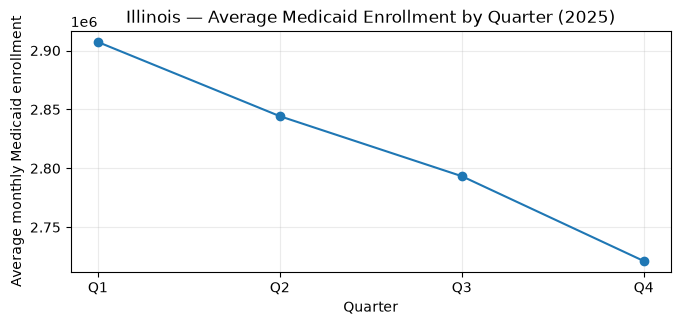

In [36]:
illinois = quarterly.loc[quarterly["state"].eq("IL")].sort_values("quarter")

plt.figure(figsize=(7, 3.5))
plt.plot(illinois["quarter"], illinois["avg_medicaid_enrollment"], marker="o")
plt.title("Illinois — Average Medicaid Enrollment by Quarter (2025)")
plt.xlabel("Quarter")
plt.ylabel("Average monthly Medicaid enrollment")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Notes for the final report

- **Unit of observation:** one state-quarter in 2025.
- **Denominator:** mean of the three `Total Medicaid Enrollment` monthly counts in that quarter.
- **Record selection:** updated (`U`) and final (`Y`) records from the October 2026 CMS release; preliminary observations excluded.
- **Data quality:** keep source footnotes and review cross-state reporting differences when interpreting the results.
- **Limitation:** enrollment counts cover all ages, while the BRFSS obesity/diabetes indicators may describe adults only. Also, number of prescriptions per enrollee is **not** the proportion of people using GLP-1 medications.

